In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [2]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


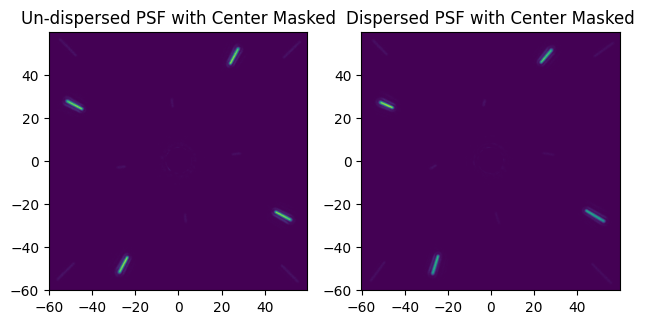

In [3]:
mag = 0.1
angle = 45

psf0 = PsfGen.polar_psf()
psf = PsfGen.polar_psf(magnitude=mag, orientation = angle)
plt.subplot(1,2,2)
imshow_field(psf)
plt.title('Dispersed PSF with Center Masked')
plt.subplot(1,2,1)
imshow_field(psf0)
plt.title('Un-dispersed PSF with Center Masked')
plt.tight_layout()
plt.show()

In [4]:
#connect the two un dispersed speckle pairs with one line. these two lines will be the two vectors that define our new coordinate basis - this way we're not beholden to the centroid position of the psf unlike pathak et al
#this basis will have to be determined upon calibration... wait a second here while I think about this

#we can't just calibrate it once because jitter will displace things, and the cropping isn't going to put the speckles in exactly the same position every time
#measuring the centroid of the PSF can be a bit nebulous, especially in bad seeing
#so how to we determine, on a frame by frame basis, the "zero dispersion basis set"?
#simple idea - two points can only have one shortest path between them, which is a line. we take the centers of the speckles and connect them. 
# --- isn't that just the same as finding the centroid of the PSF? is this necessarily a better or worse way of doing it? well, it can be done with a coronagraph, which is not nothing.

#good thing the gaussian fitter already spits out a slope that's attached to the exact position of the speckle!

In [24]:
#ok, musing over. let's draw some lines.
angle1,center1 = ADC.slice_speckle_angle(psf0,0,True)
angle3,center3 = ADC.slice_speckle_angle(psf0,2,True)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:23: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


center_of_intensity[0] 25.648058585444026
center_of_intensity[1] 48.26418797982121
lin_region_center 35
corresponding mu 35.681684882677466
relative center [0.         0.68168488]
center_of_intensity[0] -25.743786345771117
center_of_intensity[1] -48.391049486046995
lin_region_center 46
corresponding mu 41.149505481800794
relative center [11.          6.14950548]


1.8783852414942728
-0.12615787721920518


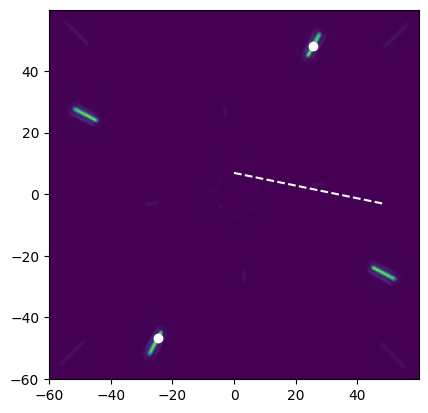

In [36]:
plt.figure()
imshow_field(psf0)
plt.plot(center1[0],center1[1],'o',color='white')
plt.plot(center3[0],center3[1],'o',color='white')

a = np.linspace(-40,40)
xs = np.array([center1[0],center3[0]])
ys = np.array([center1[1],center3[1]])
intercept, slope = np.polyfit(xs,ys,deg=1) 
print(intercept)
print(slope)
plt.plot(slope * a + intercept,'w--')


In [33]:
print(xs)
print(ys)

[ 25.76167273 -24.71886877]
[ 48.26418798 -46.55771615]
